# Logistic Regression — tuning, evaluation and test on 4 targets
Targets: **Cath** (overall CAD), **LAD**, **LCX**, **RCA**. Input: `data/processed/cad_clean.csv` produced by notebook 01 (frozen 80/20 stratified split).

Workflow: baseline → complexity / depth sweeps → feature-count sweep → GridSearchCV → RandomizedSearchCV → CV-fold study → nested CV (paper-comparable protocol) → threshold tuning → **single** test evaluation → paper methods (single / OR-rule / stacked) → permutation importance → save.

All scaling, encoding, feature selection and SMOTE sit inside one `imblearn` `Pipeline`, so every CV fold is leak-free. LAD/LCX/RCA/Cath are never inputs, except as *out-of-fold* probabilities in the paper's stacked method.

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')
import time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score, cross_validate, cross_val_predict, validation_curve)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score, average_precision_score, f1_score, recall_score,
                             precision_score, brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve, make_scorer, ConfusionMatrixDisplay)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
pd.set_option('display.width',220,'display.max_columns',60,'display.max_rows',200)
sns.set_theme(style='whitegrid'); SEED=42; M='lr'
ROOT=Path('..').resolve(); OUT=ROOT/'data'/'processed'; RES=ROOT/'results'; FIG=RES/'figures'; MOD=ROOT/'models'
for p in (RES,FIG,MOD): p.mkdir(parents=True,exist_ok=True)

## 1. Load the cleaned data and rebuild the same split

In [2]:
df = pd.read_csv(OUT/'cad_clean.csv', keep_default_na=False)
TARGETS=['Cath','LAD','LCX','RCA']; AUDIT=['Cath_original','label_corrected','n_vessels']
FEATURES=[c for c in df.columns if c not in ['patient_idx','split']+TARGETS+AUDIT]
assert not set(FEATURES)&set(TARGETS+AUDIT)
tr=df[df.split=='train']; te=df[df.split=='test']
X_tr,X_te,X_all=tr[FEATURES],te[FEATURES],df[FEATURES]
Y_tr={t:tr[t].values for t in TARGETS}; Y_te={t:te[t].values for t in TARGETS}; Y_all={t:df[t].values for t in TARGETS}
print(len(FEATURES),'features | train',X_tr.shape,'| test',X_te.shape)
pd.DataFrame({'train_pos_rate':[Y_tr[t].mean() for t in TARGETS],'test_pos_rate':[Y_te[t].mean() for t in TARGETS]},index=TARGETS).round(3)

62 features | train (242, 62) | test (61, 62)


,train_pos_rate,test_pos_rate
Cath,0.715,0.721
LAD,0.583,0.590
LCX,0.388,0.410
RCA,0.376,0.377


## 2. Preprocessing definition (identical to notebook 01)

In [3]:
num_cols=['Age','Weight','Length','BMI','BP','PR','FBS','CR','TG','LDL','HDL','BUN','ESR','HB','K','Na','WBC','Lymph','Neut','PLT','EF-TTE']
skew_cols=['FBS','TG','ESR','WBC','PLT','CR','TG_HDL','NLR','LDL_HDL']
scale_cols=[c for c in num_cols if c in FEATURES and c not in skew_cols]+['pulse_pressure_proxy','risk_factor_count','ecg_abnormal_count','symptom_score']
ordinal_cols=['VHD','Function Class','Region RWMA']; nominal_cols=['BBB','CP_type','age_group']
binary_cols=[c for c in FEATURES if c not in skew_cols+scale_cols+ordinal_cols+nominal_cols]
assert sorted(skew_cols+scale_cols+ordinal_cols+nominal_cols+binary_cols)==sorted(FEATURES)
def build_preprocessor():
    return ColumnTransformer([
        ('skew',Pipeline([('log',FunctionTransformer(np.log1p,feature_names_out='one-to-one')),('sc',StandardScaler())]),skew_cols),
        ('num',StandardScaler(),scale_cols),
        ('ord',Pipeline([('enc',OrdinalEncoder(categories=[['N','mild','Moderate','Severe'],[0,1,2,3],[0,1,2,3,4]])),('sc',StandardScaler())]),ordinal_cols),
        ('nom',OneHotEncoder(handle_unknown='ignore',sparse_output=False),nominal_cols),
        ('bin','passthrough',binary_cols)],verbose_feature_names_out=False)
# the explicit fit / fit_transform / transform sequence on this split
_p=build_preprocessor(); _a=_p.fit_transform(X_tr); _b=_p.transform(X_te)
print('fit_transform(train):',_a.shape,'| transform(test):',_b.shape)

fit_transform(train): (242, 70) | transform(test): (61, 70)


## 3. Pipeline factory, CV schemes, metric helpers

In [4]:
def make_pipe(clf):
    # prep -> univariate feature selection (k tunable, 'all' = off) -> sampler (tunable: passthrough | SMOTE) -> classifier
    return ImbPipeline([('prep',build_preprocessor()),('fs',SelectKBest(f_classif,k='all')),('sampler','passthrough'),('clf',clf)])
def new_clf(): return LogisticRegression(max_iter=5000, solver='saga', random_state=SEED)
cv5  = StratifiedKFold(5,shuffle=True,random_state=SEED)
cv52 = RepeatedStratifiedKFold(n_splits=5,n_repeats=2,random_state=SEED)
SCORING={'roc_auc':'roc_auc','average_precision':'average_precision','balanced_accuracy':'balanced_accuracy','f1':'f1','recall':'recall'}
spw={t:float((Y_tr[t]==0).sum()/(Y_tr[t]==1).sum()) for t in TARGETS}      # neg/pos ratio for scale_pos_weight
print({k:round(v,2) for k,v in spw.items()})

{'Cath': 0.4, 'LAD': 0.72, 'LCX': 1.57, 'RCA': 1.66}


In [5]:
def metrics_at(y,p,thr):
    yh=(p>=thr).astype(int); tn,fp,fn,tp=confusion_matrix(y,yh,labels=[0,1]).ravel()
    sens=tp/(tp+fn) if tp+fn else np.nan; spec=tn/(tn+fp) if tn+fp else np.nan
    return dict(threshold=float(thr),accuracy=accuracy_score(y,yh),balanced_acc=(sens+spec)/2,sensitivity=sens,specificity=spec,
                precision=precision_score(y,yh,zero_division=0),f1=f1_score(y,yh,zero_division=0),roc_auc=roc_auc_score(y,p),
                pr_auc=average_precision_score(y,p),brier=brier_score_loss(y,p),TP=tp,FP=fp,TN=tn,FN=fn)
def thr_youden(y,p):
    f,t,th=roc_curve(y,p); return float(th[np.argmax(t-f)])
def thr_sens(y,p,s=0.95):
    f,t,th=roc_curve(y,p); return float(th[np.where(t>=s)[0][0]])       # highest threshold reaching sensitivity s (max specificity)
def boot_ci(y,p,thr,B=1000,seed=SEED):
    rng=np.random.default_rng(seed); a,b=[],[]
    for _ in range(B):
        i=rng.integers(0,len(y),len(y))
        if len(set(y[i]))<2: continue
        a.append(roc_auc_score(y[i],p[i])); b.append(accuracy_score(y[i],(p[i]>=thr).astype(int)))
    return np.percentile(a,[2.5,97.5]),np.percentile(b,[2.5,97.5])

## 4. Baselines: Dummy vs default model (5-fold × 2 repeats, train only)

In [6]:
def cv_row(est,t,cv=cv52):
    r=cross_validate(est,X_tr,Y_tr[t],cv=cv,scoring=SCORING,n_jobs=-1)
    return {k.replace('test_',''):v.mean() for k,v in r.items() if k.startswith('test_')}
rows=[]
for t in TARGETS:
    rows.append({'target':t,'model':'Dummy',**cv_row(make_pipe(DummyClassifier(strategy='prior')),t)})
    rows.append({'target':t,'model':'default '+M,**cv_row(make_pipe(new_clf()),t)})
baseline=pd.DataFrame(rows).set_index(['target','model']).round(3); baseline

roc_auc  average_precision  balanced_accuracy     f1  recall
target model                                                                   
Cath   Dummy         0.500              0.715              0.500  0.834   1.000
       default lr    0.940              0.977              0.818  0.903   0.913
LAD    Dummy         0.500              0.583              0.500  0.736   1.000
       default lr    0.850              0.894              0.774  0.812   0.820
LCX    Dummy         0.500              0.388              0.500  0.000   0.000
       default lr    0.642              0.543              0.589  0.486   0.472
RCA    Dummy         0.500              0.376              0.500  0.000   0.000
       default lr    0.746              0.611              0.652  0.557   0.539

## 5. Complexity / depth sweeps (train vs CV ROC-AUC)

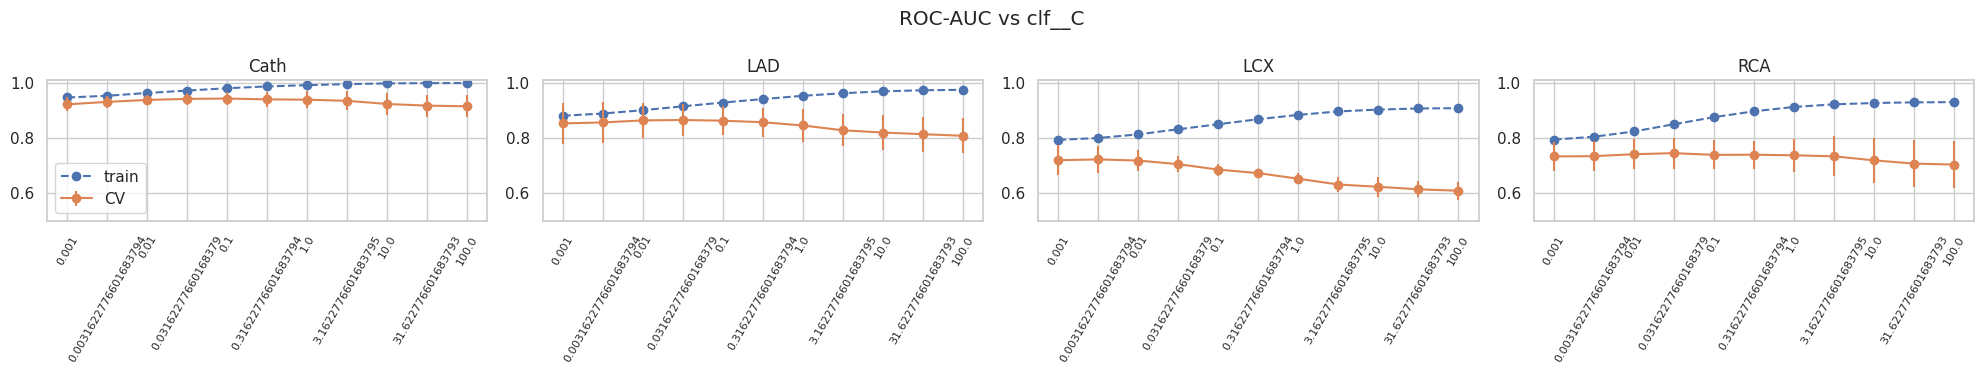

In [7]:
def sweep(param,values,title,fname):
    fig,axes=plt.subplots(1,4,figsize=(20,3.8)); out={}
    for ax,t in zip(axes,TARGETS):
        tr_s,cv_s=validation_curve(make_pipe(new_clf()),X_tr,Y_tr[t],param_name=param,param_range=values,cv=cv5,scoring='roc_auc',n_jobs=-1)
        xs=np.arange(len(values)); out[t]=pd.DataFrame({'value':[str(v) for v in values],'train_auc':tr_s.mean(1),'cv_auc':cv_s.mean(1),'cv_std':cv_s.std(1)})
        ax.plot(xs,tr_s.mean(1),'o--',label='train'); ax.errorbar(xs,cv_s.mean(1),cv_s.std(1),fmt='o-',label='CV')
        ax.set_xticks(xs); ax.set_xticklabels([str(v) for v in values],rotation=60,fontsize=8); ax.set_title(f'{t}'); ax.set_ylim(0.5,1.01)
    axes[0].legend(); fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG/f'lr_{fname}.png',dpi=110); plt.show(); return out
p1,v1=('clf__C', np.logspace(-3,2,11))
sw1=sweep(p1,v1,f'ROC-AUC vs {p1}','sweep1')

In [8]:
pd.concat({t:sw1[t].set_index('value')[['train_auc','cv_auc']] for t in TARGETS},axis=1).round(3)

Cath              LAD              LCX              RCA       
                      train_auc cv_auc train_auc cv_auc train_auc cv_auc train_auc cv_auc
value                                                                                    
0.001                     0.948  0.923     0.881  0.853     0.793  0.719     0.794  0.733
0.0031622776601683794     0.954  0.932     0.889  0.857     0.800  0.722     0.805  0.734
0.01                      0.964  0.939     0.901  0.864     0.814  0.718     0.824  0.741
0.03162277660168379       0.973  0.943     0.915  0.866     0.832  0.705     0.850  0.745
0.1                       0.981  0.944     0.929  0.863     0.851  0.685     0.876  0.739
0.31622776601683794       0.988  0.941     0.942  0.858     0.869  0.672     0.897  0.739
1.0                       0.992  0.940     0.954  0.846     0.884  0.652     0.913  0.737
3.1622776601683795        0.996  0.935     0.963  0.828     0.897  0.631     0.923  0.734
10.0                      0.999  0.924     0.970  0.820     0.904  0.623     0.927  0.719
31.622776601683793        1.000  0.918     0.974  0.814     0.908  0.614     0.930  0.707
100.0                     1.000  0.916     0.975  0.808     0.909  0.608     0.931  0.704

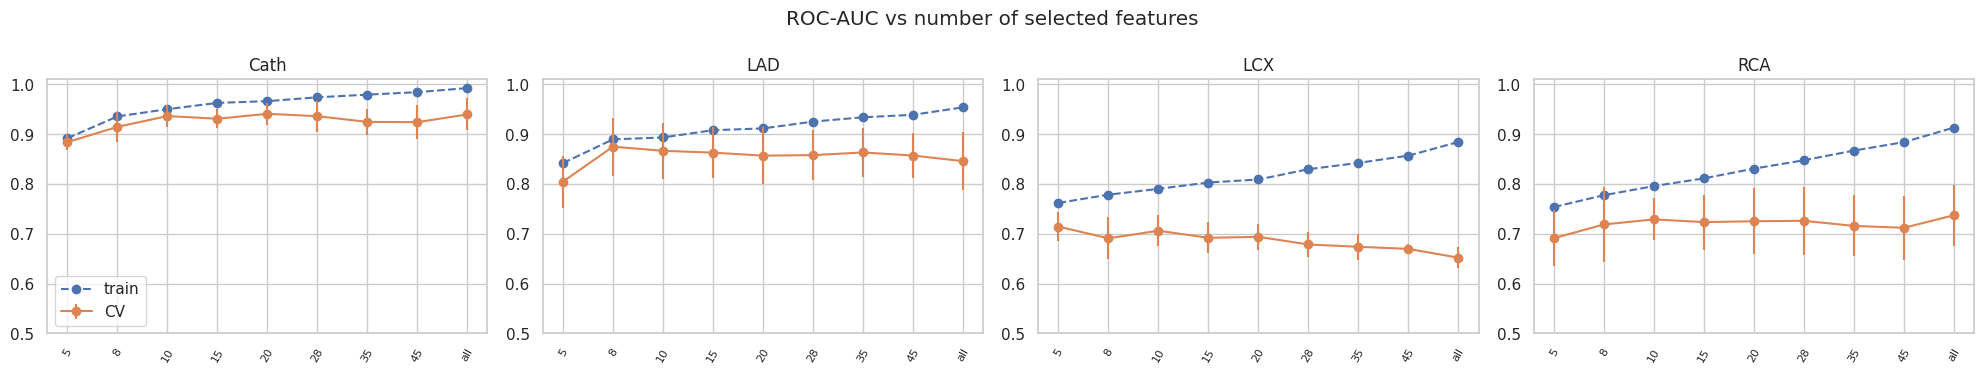

Cath              LAD              LCX              RCA       
      train_auc cv_auc train_auc cv_auc train_auc cv_auc train_auc cv_auc
value                                                                    
5         0.892  0.884     0.842  0.805     0.762  0.714     0.754  0.691
8         0.936  0.915     0.890  0.875     0.778  0.691     0.778  0.719
10        0.950  0.936     0.893  0.867     0.790  0.706     0.796  0.729
15        0.963  0.931     0.908  0.863     0.803  0.692     0.811  0.723
20        0.966  0.941     0.911  0.857     0.809  0.694     0.831  0.725
28        0.974  0.936     0.925  0.858     0.830  0.679     0.848  0.726
35        0.979  0.925     0.934  0.863     0.842  0.674     0.867  0.716
45        0.984  0.924     0.939  0.857     0.857  0.670     0.884  0.712
all       0.992  0.940     0.954  0.846     0.884  0.652     0.913  0.737

In [9]:
# number of selected features (SelectKBest inside the pipeline)
ks=[5,8,10,15,20,28,35,45,'all']
sw3=sweep('fs__k',ks,'ROC-AUC vs number of selected features','sweep_k')
pd.concat({t:sw3[t].set_index('value')[['train_auc','cv_auc']] for t in TARGETS},axis=1).round(3)

## 6. GridSearchCV (focused grid, 5×2 repeated CV, 5 metrics, refit on ROC-AUC)

In [10]:
def param_grid(spw):
    base = {'fs__k':[10,20,35,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)],'clf__class_weight':[None,'balanced'],'clf__C':list(np.logspace(-3,2,9))}
    return [dict(base,clf__penalty=['l2']), dict(base,clf__penalty=['l1']), dict(base,clf__penalty=['elasticnet'],clf__l1_ratio=[0.2,0.5,0.8])]
def param_space(spw):
    common = {'fs__k':[8,10,15,20,28,35,45,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)],'clf__class_weight':[None,'balanced'],'clf__C':loguniform(1e-3,1e2)}
    return [dict(common,clf__penalty=['l2']), dict(common,clf__penalty=['l1']), dict(common,clf__penalty=['elasticnet'],clf__l1_ratio=uniform(0.05,0.9))]
for t in TARGETS:
    g=param_grid(spw[t]); size=int(np.sum([np.prod([len(v) for v in d.values()]) for d in (g if isinstance(g,list) else [g])]))
    print(t,'grid combinations:',size,'-> fits:',size*10)

Cath grid combinations: 720 -> fits: 7200
LAD grid combinations: 720 -> fits: 7200
LCX grid combinations: 720 -> fits: 7200
RCA grid combinations: 720 -> fits: 7200


In [11]:
searches={t:{} for t in TARGETS}
for t in TARGETS:
    t0=time.time()
    gs=GridSearchCV(make_pipe(new_clf()),param_grid(spw[t]),scoring=SCORING,refit='roc_auc',cv=cv52,n_jobs=-1,verbose=0)
    gs.fit(X_tr,Y_tr[t]); searches[t]['grid']=gs
    pd.DataFrame(gs.cv_results_).to_csv(RES/f'{M}_cv_grid_{t}.csv',index=False)
    print(f'{t}: best CV AUC={gs.best_score_:.4f}  ({time.time()-t0:.0f}s, {len(gs.cv_results_["params"])} combos)')

Cath: best CV AUC=0.9486  (38s, 720 combos)


LAD: best CV AUC=0.8805  (34s, 720 combos)


LCX: best CV AUC=0.7181  (33s, 720 combos)


RCA: best CV AUC=0.7519  (36s, 720 combos)


## 7. RandomizedSearchCV (wide space, many more combinations)

In [12]:
N_ITER=250
for t in TARGETS:
    t0=time.time()
    rs=RandomizedSearchCV(make_pipe(new_clf()),param_space(spw[t]),n_iter=N_ITER,scoring=SCORING,refit='roc_auc',cv=cv52,n_jobs=-1,random_state=SEED,verbose=0)
    rs.fit(X_tr,Y_tr[t]); searches[t]['random']=rs
    pd.DataFrame(rs.cv_results_).to_csv(RES/f'{M}_cv_random_{t}.csv',index=False)
    print(f'{t}: best CV AUC={rs.best_score_:.4f}  ({time.time()-t0:.0f}s)')

Cath: best CV AUC=0.9466  (11s)


LAD: best CV AUC=0.8800  (11s)


LCX: best CV AUC=0.7175  (10s)


RCA: best CV AUC=0.7518  (11s)


## 8. Pick the best configuration per target

In [13]:
best_est,rows={},[]
for t in TARGETS:
    g,r=searches[t]['grid'],searches[t]['random']
    win,name=(g,'grid') if g.best_score_>=r.best_score_ else (r,'random')
    best_est[t]=win.best_estimator_; i=win.best_index_; cr=win.cv_results_
    rows.append({'target':t,'winner':name,'cv_roc_auc':cr['mean_test_roc_auc'][i],'cv_pr_auc':cr['mean_test_average_precision'][i],
                 'cv_bal_acc':cr['mean_test_balanced_accuracy'][i],'cv_f1':cr['mean_test_f1'][i],'cv_recall':cr['mean_test_recall'][i],
                 'grid_auc':g.best_score_,'random_auc':r.best_score_})
best_tbl=pd.DataFrame(rows).set_index('target').round(4); best_tbl

,winner,cv_roc_auc,cv_pr_auc,cv_bal_acc,cv_f1,cv_recall,grid_auc,random_auc
target,,,,,,,,
Cath,grid,0.9486,0.9804,0.8510,0.8981,0.8697,0.9486,0.9466
LAD,grid,0.8805,0.9101,0.7917,0.8138,0.7910,0.8805,0.8800
LCX,grid,0.7181,0.5997,0.6614,0.5954,0.6330,0.7181,0.7175
RCA,grid,0.7519,0.6113,0.6949,0.6321,0.7143,0.7519,0.7518


In [14]:
best_params=pd.DataFrame({t:{k:str(v) for k,v in best_est[t].get_params().items() if k.startswith(('clf__','fs__k','sampler'))
                                 and not isinstance(v,(dict,)) and k not in ('sampler__random_state',)} for t in TARGETS}); best_params

,Cath,LAD,LCX,RCA
sampler,passthrough,passthrough,passthrough,passthrough
fs__k,all,35,all,all
clf__C,0.07498942093324558,0.31622776601683794,0.004216965034285823,0.31622776601683794
clf__class_weight,balanced,balanced,balanced,balanced
clf__dual,False,False,False,False
clf__fit_intercept,True,True,True,True
clf__intercept_scaling,1,1,1,1
clf__l1_ratio,None,None,None,0.2
clf__max_iter,5000,5000,5000,5000
clf__multi_class,deprecated,deprecated,deprecated,deprecated


In [15]:
# top-5 combinations per target (from both searches)
for t in TARGETS:
    parts=[]
    for nm in ('grid','random'):
        d=pd.DataFrame(searches[t][nm].cv_results_); d['search']=nm; parts.append(d)
    d=pd.concat(parts).sort_values('mean_test_roc_auc',ascending=False).head(5)
    print('==',t); print(d[['search','mean_test_roc_auc','std_test_roc_auc','mean_test_balanced_accuracy','mean_test_recall','params']].to_string(index=False,max_colwidth=160))

== Cath
search  mean_test_roc_auc  std_test_roc_auc  mean_test_balanced_accuracy  mean_test_recall                                                                                                                                                           params
  grid           0.948579          0.022370                     0.851041          0.869664                                 {'clf__C': 0.07498942093324558, 'clf__class_weight': 'balanced', 'clf__penalty': 'l2', 'fs__k': 'all', 'sampler': 'passthrough'}
  grid           0.947307          0.020844                     0.811955          0.944790                                       {'clf__C': 0.07498942093324558, 'clf__class_weight': None, 'clf__penalty': 'l2', 'fs__k': 'all', 'sampler': 'passthrough'}
random           0.946632          0.024653                     0.817944          0.941933 {'clf__C': 0.16949768237884735, 'clf__class_weight': None, 'clf__l1_ratio': 0.10227525095137951, 'clf__penalty': 'elasticnet', 'fs__k': 'all', 's

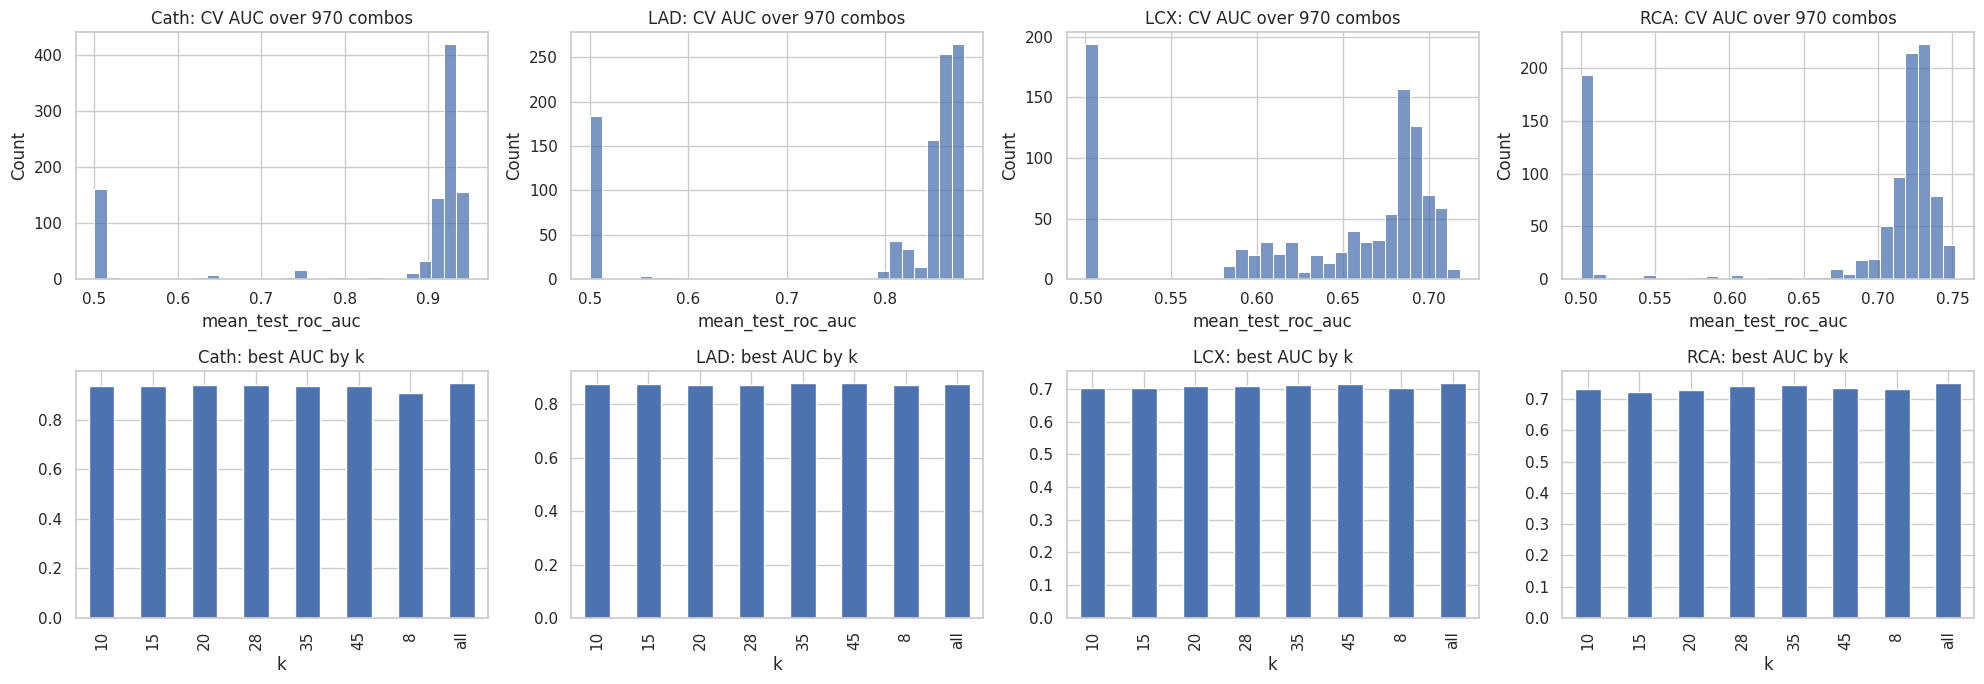

In [16]:
# distribution of CV AUC over all tried combinations + effect of depth if it was tuned
fig,axes=plt.subplots(2,4,figsize=(20,7))
for j,t in enumerate(TARGETS):
    d=pd.concat([pd.DataFrame(searches[t][n_].cv_results_) for n_ in ('grid','random')])
    sns.histplot(d.mean_test_roc_auc,bins=30,ax=axes[0,j]); axes[0,j].set_title(f'{t}: CV AUC over {len(d)} combos')
    col=[c for c in d.columns if c.endswith('max_depth')]
    if col:
        dd=d.assign(depth=d[col[0]].astype(str)).groupby('depth').mean_test_roc_auc.agg(['mean','max'])
        dd=dd.loc[sorted(dd.index,key=lambda s:(s=='None',float(s) if s not in ('None',) else 99))]
        dd.plot(ax=axes[1,j],marker='o'); axes[1,j].set_title(f'{t}: AUC by max_depth')
    else:
        d.assign(k=d['param_fs__k'].astype(str)).groupby('k').mean_test_roc_auc.max().plot.bar(ax=axes[1,j]); axes[1,j].set_title(f'{t}: best AUC by k')
plt.tight_layout(); plt.savefig(FIG/f'{M}_search_overview.png',dpi=110); plt.show()

## 9. Effect of the number of CV folds (best configuration, train only)

In [17]:
schemes={'3-fold':StratifiedKFold(3,shuffle=True,random_state=SEED),'5-fold':StratifiedKFold(5,shuffle=True,random_state=SEED),
         '7-fold':StratifiedKFold(7,shuffle=True,random_state=SEED),'10-fold':StratifiedKFold(10,shuffle=True,random_state=SEED),
         '5x3 repeated':RepeatedStratifiedKFold(n_splits=5,n_repeats=3,random_state=SEED),'10x3 repeated':RepeatedStratifiedKFold(n_splits=10,n_repeats=3,random_state=SEED)}
rows=[]
for t in TARGETS:
    for nm,cv in schemes.items():
        s=cross_validate(clone(best_est[t]),X_tr,Y_tr[t],cv=cv,scoring={'auc':'roc_auc','acc':'accuracy','bal':'balanced_accuracy'},n_jobs=-1)
        rows.append({'target':t,'cv':nm,'auc_mean':s['test_auc'].mean(),'auc_std':s['test_auc'].std(),'acc_mean':s['test_acc'].mean(),'bal_acc_mean':s['test_bal'].mean()})
fold_tbl=pd.DataFrame(rows); fold_tbl.to_csv(RES/f'{M}_cv_fold_study.csv',index=False)
fold_tbl.pivot(index='cv',columns='target',values='auc_mean').loc[list(schemes)].round(4)

target,Cath,LAD,LCX,RCA
cv,,,,
3-fold,0.9384,0.8682,0.7059,0.7586
5-fold,0.9447,0.8753,0.7222,0.7456
7-fold,0.9521,0.8826,0.7195,0.7546
10-fold,0.9578,0.8791,0.7228,0.7523
5x3 repeated,0.9473,0.8756,0.7202,0.7476
10x3 repeated,0.9484,0.8810,0.7230,0.7598


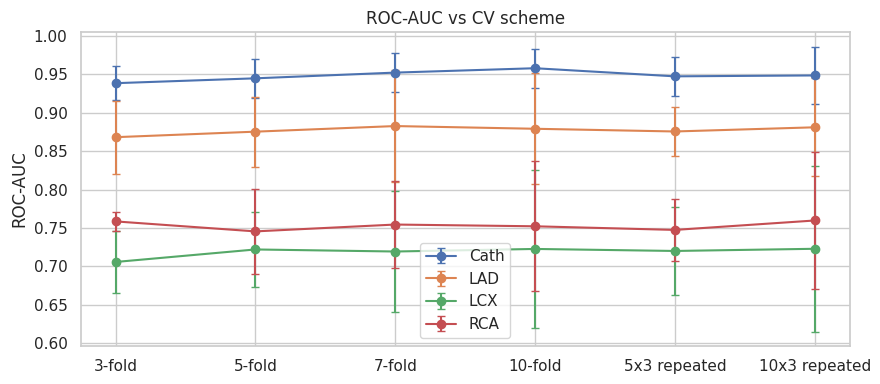

In [18]:
fig,ax=plt.subplots(figsize=(9,4))
for t in TARGETS:
    d=fold_tbl[fold_tbl.target==t]; ax.errorbar(range(len(d)),d.auc_mean,d.auc_std,marker='o',label=t,capsize=3)
ax.set_xticks(range(len(schemes))); ax.set_xticklabels(list(schemes)); ax.set_ylabel('ROC-AUC'); ax.legend(); ax.set_title('ROC-AUC vs CV scheme'); plt.tight_layout(); plt.show()

## 10. Nested CV on all 303 patients (paper-comparable protocol)
The paper reports 10-fold CV on all data. Here every outer fold tunes hyper-parameters (feature count, sampler, model parameters) on its own training part only, so the numbers are not tuned on the fold that scores them. Threshold = 0.5.

In [19]:
spec_scorer=make_scorer(recall_score,pos_label=0)
NEST_SCORING={'accuracy':'accuracy','balanced_acc':'balanced_accuracy','sensitivity':'recall','specificity':spec_scorer,'precision':'precision','f1':'f1','roc_auc':'roc_auc'}
outer=StratifiedKFold(10,shuffle=True,random_state=SEED); nested_rows=[]
for t in TARGETS:
    t0=time.time()
    inner=RandomizedSearchCV(make_pipe(new_clf()),param_space(spw[t]),n_iter=30,scoring='roc_auc',cv=StratifiedKFold(3,shuffle=True,random_state=SEED),n_jobs=1,random_state=SEED)
    r=cross_validate(inner,X_all,Y_all[t],cv=outer,scoring=NEST_SCORING,n_jobs=-1)
    row={'target':t}; row.update({k.replace('test_',''):r[k].mean() for k in r if k.startswith('test_')}); row.update({k.replace('test_','')+'_std':r[k].std() for k in r if k.startswith('test_')})
    nested_rows.append(row); print(t,f"acc={row['accuracy']:.3f} sens={row['sensitivity']:.3f} spec={row['specificity']:.3f} auc={row['roc_auc']:.3f} ({time.time()-t0:.0f}s)")
nested=pd.DataFrame(nested_rows).set_index('target'); nested.to_csv(RES/f'{M}_nested_cv.csv'); nested[[c for c in nested if not c.endswith('_std')]].round(4)

Cath acc=0.865 sens=0.917 spec=0.733 auc=0.939 (4s)


LAD acc=0.773 sens=0.831 spec=0.694 auc=0.837 (3s)


LCX acc=0.631 sens=0.333 spec=0.822 auc=0.710 (3s)


RCA acc=0.644 sens=0.475 spec=0.746 auc=0.715 (3s)


,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc
target,,,,,,,
Cath,0.8648,0.8251,0.9169,0.7333,0.8988,0.9066,0.9390
LAD,0.7728,0.7625,0.8314,0.6936,0.7989,0.8095,0.8367
LCX,0.6310,0.5778,0.3333,0.8222,0.3835,0.3514,0.7100
RCA,0.6435,0.6106,0.4750,0.7462,0.4992,0.4670,0.7148


## 11. Decision threshold from out-of-fold *train* probabilities

In [20]:
def oof_proba(est,X,y,seeds=(0,1,2)):
    P=np.zeros(len(y))
    for s in seeds: P+=cross_val_predict(clone(est),X,y,cv=StratifiedKFold(5,shuffle=True,random_state=s),method='predict_proba',n_jobs=-1)[:,1]
    return P/len(seeds)
oof={t:oof_proba(best_est[t],X_tr,Y_tr[t]) for t in TARGETS}
THR={t:{'default_0.5':0.5,'youden':thr_youden(Y_tr[t],oof[t]),'sens>=0.95':thr_sens(Y_tr[t],oof[t],0.95)} for t in TARGETS}
pd.DataFrame(THR).T.round(3)

,default_0.5,youden,sens>=0.95
Cath,0.5,0.549,0.317
LAD,0.5,0.491,0.296
LCX,0.5,0.479,0.420
RCA,0.5,0.344,0.212


In [21]:
pd.DataFrame({(t,k):metrics_at(Y_tr[t],oof[t],v) for t in TARGETS for k,v in THR[t].items()}).T[['threshold','accuracy','sensitivity','specificity','roc_auc']].round(3)

threshold  accuracy  sensitivity  specificity  roc_auc
Cath default_0.5      0.500     0.893        0.890        0.899    0.948
     youden           0.549     0.880        0.855        0.942    0.948
     sens>=0.95       0.317     0.876        0.960        0.667    0.948
LAD  default_0.5      0.500     0.777        0.787        0.762    0.871
     youden           0.491     0.789        0.816        0.752    0.871
     sens>=0.95       0.296     0.810        0.950        0.614    0.871
LCX  default_0.5      0.500     0.669        0.638        0.689    0.725
     youden           0.479     0.678        0.766        0.622    0.725
     sens>=0.95       0.420     0.545        0.957        0.284    0.725
RCA  default_0.5      0.500     0.694        0.659        0.715    0.741
     youden           0.344     0.661        0.846        0.550    0.741
     sens>=0.95       0.212     0.587        0.956        0.364    0.741

## 12. Final evaluation on the held-out test set (touched once)

In [22]:
test_proba={}
for t in TARGETS:
    best_est[t].fit(X_tr,Y_tr[t]); test_proba[t]=best_est[t].predict_proba(X_te)[:,1]
rows=[]
for t in TARGETS:
    for k,thr in THR[t].items():
        m=metrics_at(Y_te[t],test_proba[t],thr); (alo,ahi),(clo,chi)=boot_ci(Y_te[t],test_proba[t],thr)
        rows.append({'target':t,'strategy':'direct','threshold_rule':k,**m,'auc_ci':f'[{alo:.3f},{ahi:.3f}]','acc_ci':f'[{clo:.3f},{chi:.3f}]'})
test_tbl=pd.DataFrame(rows); test_tbl.to_csv(RES/f'{M}_test_metrics_direct.csv',index=False)
test_tbl[['target','threshold_rule','threshold','accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc','brier','auc_ci','acc_ci']].round(3)

,target,threshold_rule,threshold,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,auc_ci,acc_ci
0,Cath,default_0.5,0.500,0.852,0.826,0.886,0.765,0.907,0.897,0.928,0.973,0.106,"[0.857,0.980]","[0.754,0.934]"
1,Cath,youden,0.549,0.836,0.814,0.864,0.765,0.905,0.884,0.928,0.973,0.106,"[0.857,0.980]","[0.738,0.918]"
2,Cath,sens>=0.95,0.317,0.869,0.801,0.955,0.647,0.875,0.913,0.928,0.973,0.106,"[0.857,0.980]","[0.770,0.935]"
3,LAD,default_0.5,0.500,0.623,0.619,0.639,0.600,0.697,0.667,0.762,0.832,0.196,"[0.634,0.880]","[0.492,0.754]"
4,LAD,youden,0.491,0.656,0.647,0.694,0.600,0.714,0.704,0.762,0.832,0.196,"[0.634,0.880]","[0.525,0.771]"
5,LAD,sens>=0.95,0.296,0.754,0.712,0.944,0.480,0.723,0.819,0.762,0.832,0.196,"[0.634,0.880]","[0.639,0.852]"
6,LCX,default_0.5,0.500,0.656,0.653,0.640,0.667,0.571,0.604,0.754,0.704,0.219,"[0.625,0.872]","[0.541,0.771]"
7,LCX,youden,0.479,0.639,0.652,0.720,0.583,0.545,0.621,0.754,0.704,0.219,"[0.625,0.872]","[0.525,0.754]"
8,LCX,sens>=0.95,0.420,0.590,0.653,1.000,0.306,0.500,0.667,0.754,0.704,0.219,"[0.625,0.872]","[0.475,0.705]"
9,RCA,default_0.5,0.500,0.590,0.594,0.609,0.579,0.467,0.528,0.665,0.586,0.247,"[0.515,0.799]","[0.459,0.721]"


In [23]:
# majority-class reference on the same test set
pd.DataFrame({t:{'majority-class accuracy':max(Y_te[t].mean(),1-Y_te[t].mean()),'model accuracy (youden)':test_tbl[(test_tbl.target==t)&(test_tbl.threshold_rule=='youden')].accuracy.iloc[0]} for t in TARGETS}).T.round(3)

,majority-class accuracy,model accuracy (youden)
Cath,0.721,0.836
LAD,0.590,0.656
LCX,0.590,0.639
RCA,0.623,0.557


## 13. Curves and confusion matrices

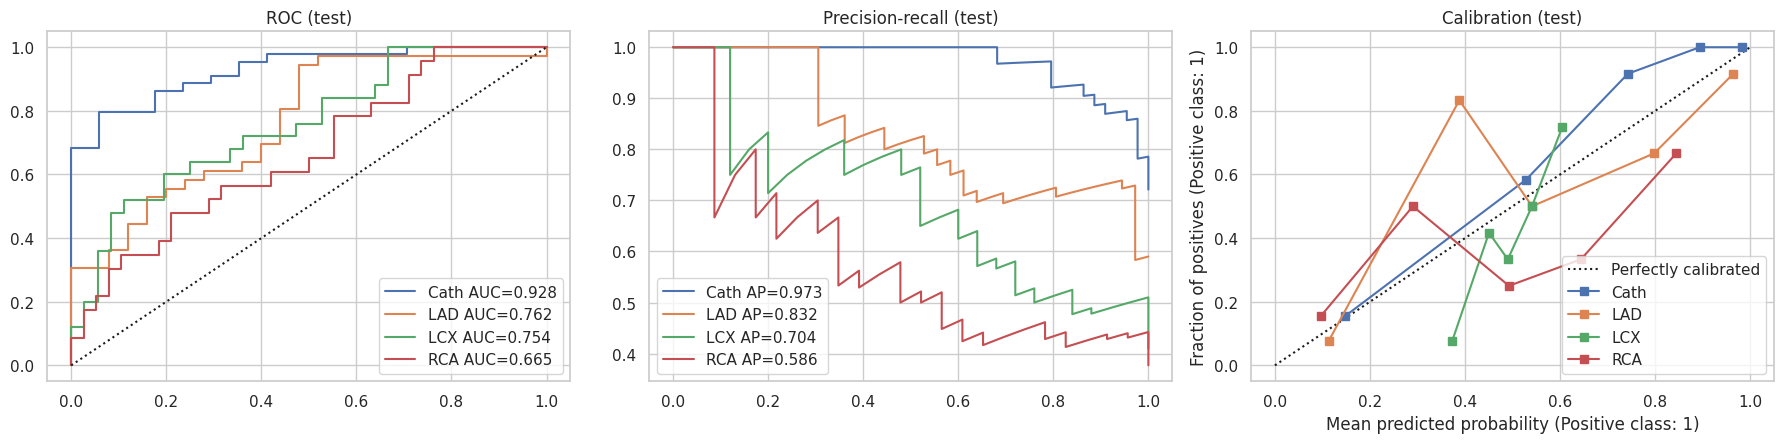

In [24]:
fig,axes=plt.subplots(1,3,figsize=(18,4.6))
for t in TARGETS:
    f,s,_=roc_curve(Y_te[t],test_proba[t]); axes[0].plot(f,s,label=f'{t} AUC={roc_auc_score(Y_te[t],test_proba[t]):.3f}')
    p,r,_=precision_recall_curve(Y_te[t],test_proba[t]); axes[1].plot(r,p,label=f'{t} AP={average_precision_score(Y_te[t],test_proba[t]):.3f}')
    CalibrationDisplay.from_predictions(Y_te[t],test_proba[t],n_bins=5,strategy='quantile',ax=axes[2],name=t)
axes[0].plot([0,1],[0,1],'k:'); axes[0].set_title('ROC (test)'); axes[1].set_title('Precision-recall (test)'); axes[2].set_title('Calibration (test)')
for a in axes[:2]: a.legend()
plt.tight_layout(); plt.savefig(FIG/f'{M}_curves.png',dpi=110); plt.show()

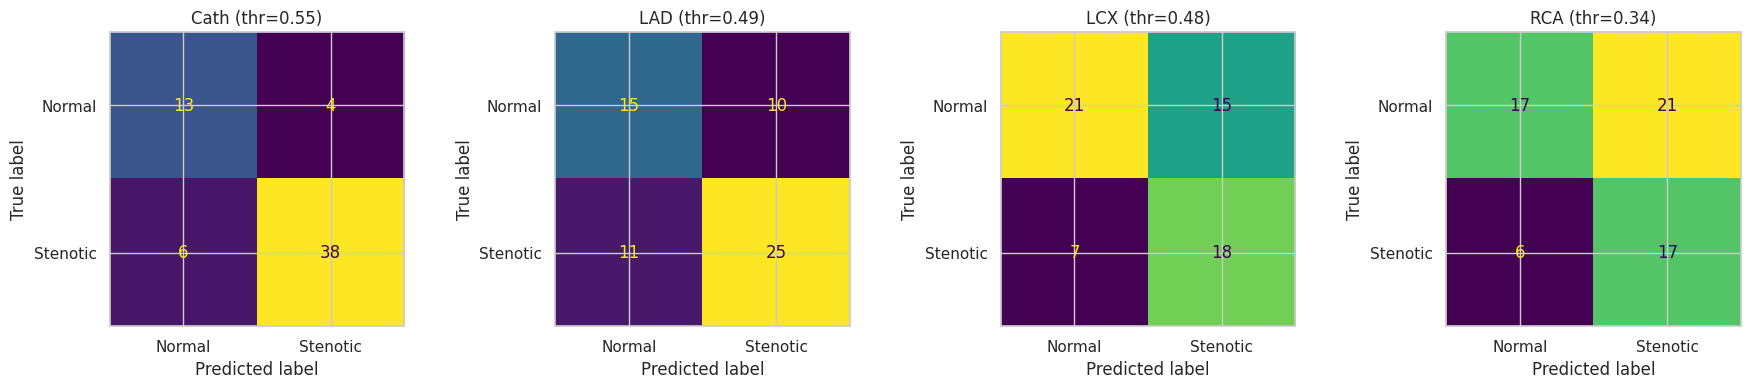

In [25]:
fig,axes=plt.subplots(1,4,figsize=(18,4))
for ax,t in zip(axes,TARGETS):
    thr=THR[t]['youden']; ConfusionMatrixDisplay.from_predictions(Y_te[t],(test_proba[t]>=thr).astype(int),ax=ax,colorbar=False,display_labels=['Normal','Stenotic']); ax.set_title(f'{t} (thr={thr:.2f})')
plt.tight_layout(); plt.savefig(FIG/f'{M}_confusion.png',dpi=110); plt.show()

## 14. Paper methods on this model family
1. **Single classifier** – Cath model only (section 12).
2. **Three-classifier OR rule** – `CT = LAD ∨ LCX ∨ RCA` (Eq. 1 of the paper).
3. **Feature-engineering (stacked) method** – out-of-fold probabilities of the LAD/LCX/RCA/CAD models are appended to the clinical features and a final CAD classifier is trained on them. Train probabilities are out-of-fold, test probabilities come from models fitted on the full train set.

In [26]:
# 2) OR rule
rows=[]
for rule in ('default_0.5','youden'):
    pred=np.zeros(len(te),int)
    for t in ['LAD','LCX','RCA']: pred|=(test_proba[t]>=THR[t][rule]).astype(int)
    score=1-np.prod([1-test_proba[t] for t in ['LAD','LCX','RCA']],axis=0)               # P(at least one stenotic), independence assumption
    yh=pred; tn,fp,fn,tp=confusion_matrix(Y_te['Cath'],yh,labels=[0,1]).ravel()
    rows.append({'target':'Cath','strategy':'OR-rule','threshold_rule':rule,'accuracy':accuracy_score(Y_te['Cath'],yh),'balanced_acc':balanced_accuracy_score(Y_te['Cath'],yh),
                 'sensitivity':tp/(tp+fn),'specificity':tn/(tn+fp),'precision':precision_score(Y_te['Cath'],yh,zero_division=0),'f1':f1_score(Y_te['Cath'],yh),
                 'roc_auc':roc_auc_score(Y_te['Cath'],score),'pr_auc':average_precision_score(Y_te['Cath'],score),'brier':brier_score_loss(Y_te['Cath'],score),'TP':tp,'FP':fp,'TN':tn,'FN':fn})
or_tbl=pd.DataFrame(rows); or_tbl.round(3)

,target,strategy,threshold_rule,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,TP,FP,TN,FN
0,Cath,OR-rule,default_0.5,0.787,0.744,0.841,0.647,0.86,0.851,0.918,0.97,0.137,37,6,11,7
1,Cath,OR-rule,youden,0.836,0.778,0.909,0.647,0.87,0.889,0.918,0.97,0.137,40,6,11,4


In [27]:
# 3) stacked method
PCOLS=['p_LAD','p_LCX','p_RCA','p_CAD']
oof_tr={t:cross_val_predict(clone(best_est[t]),X_tr,Y_tr[t],cv=StratifiedKFold(5,shuffle=True,random_state=SEED),method='predict_proba',n_jobs=-1)[:,1] for t in TARGETS}
def augment(X,P):
    A=X.copy()
    for c,t in zip(PCOLS,['LAD','LCX','RCA','Cath']): A[c]=P[t]
    return A
Xa_tr=augment(X_tr,oof_tr); Xa_te=augment(X_te,test_proba)
def meta_pipe():
    p=clone(best_est['Cath']); p.set_params(prep=ColumnTransformer([('base',build_preprocessor(),FEATURES),('probs','passthrough',PCOLS)],verbose_feature_names_out=False))
    return p
mg=GridSearchCV(meta_pipe(),{'fs__k':[4,8,12,20,32,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)]},scoring='roc_auc',cv=cv52,n_jobs=-1).fit(Xa_tr,Y_tr['Cath'])
meta=mg.best_estimator_; print('stacked CV AUC:',round(mg.best_score_,4),'| params:',{k:v for k,v in mg.best_params_.items()})
oof_meta=oof_proba(meta,Xa_tr,Y_tr['Cath']); thr_meta={'default_0.5':0.5,'youden':thr_youden(Y_tr['Cath'],oof_meta),'sens>=0.95':thr_sens(Y_tr['Cath'],oof_meta,0.95)}
meta.fit(Xa_tr,Y_tr['Cath']); p_meta=meta.predict_proba(Xa_te)[:,1]
st=pd.DataFrame([{'target':'Cath','strategy':'stacked (paper FE)','threshold_rule':k,**metrics_at(Y_te['Cath'],p_meta,v)} for k,v in thr_meta.items()]); st.round(3)

stacked CV AUC: 0.9469 | params: {'fs__k': 'all', 'sampler': 'passthrough'}


,target,strategy,threshold_rule,threshold,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,TP,FP,TN,FN
0,Cath,stacked (paper FE),default_0.5,0.500,0.820,0.785,0.864,0.706,0.884,0.874,0.928,0.973,0.105,38,5,12,6
1,Cath,stacked (paper FE),youden,0.555,0.852,0.844,0.864,0.824,0.927,0.894,0.928,0.973,0.105,38,3,14,6
2,Cath,stacked (paper FE),sens>=0.95,0.314,0.869,0.801,0.955,0.647,0.875,0.913,0.928,0.973,0.105,42,6,11,2


In [28]:
# compare the three strategies for CAD with the paper's SVM numbers (10-fold CV on 500 patients; ours: held-out test of 61)
paper=pd.DataFrame([{'strategy':'PAPER single (SVM)','accuracy':.850,'sensitivity':.894,'specificity':.768,'roc_auc':.81},
                    {'strategy':'PAPER three-classifier (SVM)','accuracy':.810,'sensitivity':.814,'specificity':.798,'roc_auc':.87},
                    {'strategy':'PAPER feature engineering (SVM)','accuracy':.964,'sensitivity':1.0,'specificity':.881,'roc_auc':.92}])
ours=pd.concat([test_tbl[test_tbl.target=='Cath'].assign(strategy=lambda d:'direct @'+d.threshold_rule),or_tbl.assign(strategy=lambda d:'OR-rule @'+d.threshold_rule),
                st.assign(strategy=lambda d:'stacked @'+d.threshold_rule)])[['strategy','accuracy','sensitivity','specificity','roc_auc']]
cmp_tbl=pd.concat([paper,ours.assign(strategy=lambda d:'OURS '+M+' '+d.strategy)]).set_index('strategy'); cmp_tbl.round(3)

,accuracy,sensitivity,specificity,roc_auc
strategy,,,,
PAPER single (SVM),0.850,0.894,0.768,0.810
PAPER three-classifier (SVM),0.810,0.814,0.798,0.870
PAPER feature engineering (SVM),0.964,1.000,0.881,0.920
OURS lr direct @default_0.5,0.852,0.886,0.765,0.928
OURS lr direct @youden,0.836,0.864,0.765,0.928
OURS lr direct @sens>=0.95,0.869,0.955,0.647,0.928
OURS lr OR-rule @default_0.5,0.787,0.841,0.647,0.918
OURS lr OR-rule @youden,0.836,0.909,0.647,0.918
OURS lr stacked @default_0.5,0.820,0.864,0.706,0.928


In [29]:
all_rows=pd.concat([test_tbl,or_tbl,st]); all_rows.to_csv(RES/f'{M}_test_metrics.csv',index=False)
nested.loc[['Cath']].round(3).rename(index={'Cath':'OURS nested 10-fold CV (303 pts, thr 0.5)'})[['accuracy','sensitivity','specificity','roc_auc']]

,accuracy,sensitivity,specificity,roc_auc
target,,,,
"OURS nested 10-fold CV (303 pts, thr 0.5)",0.865,0.917,0.733,0.939


## 15. Permutation importance on the test set (raw features, per target)

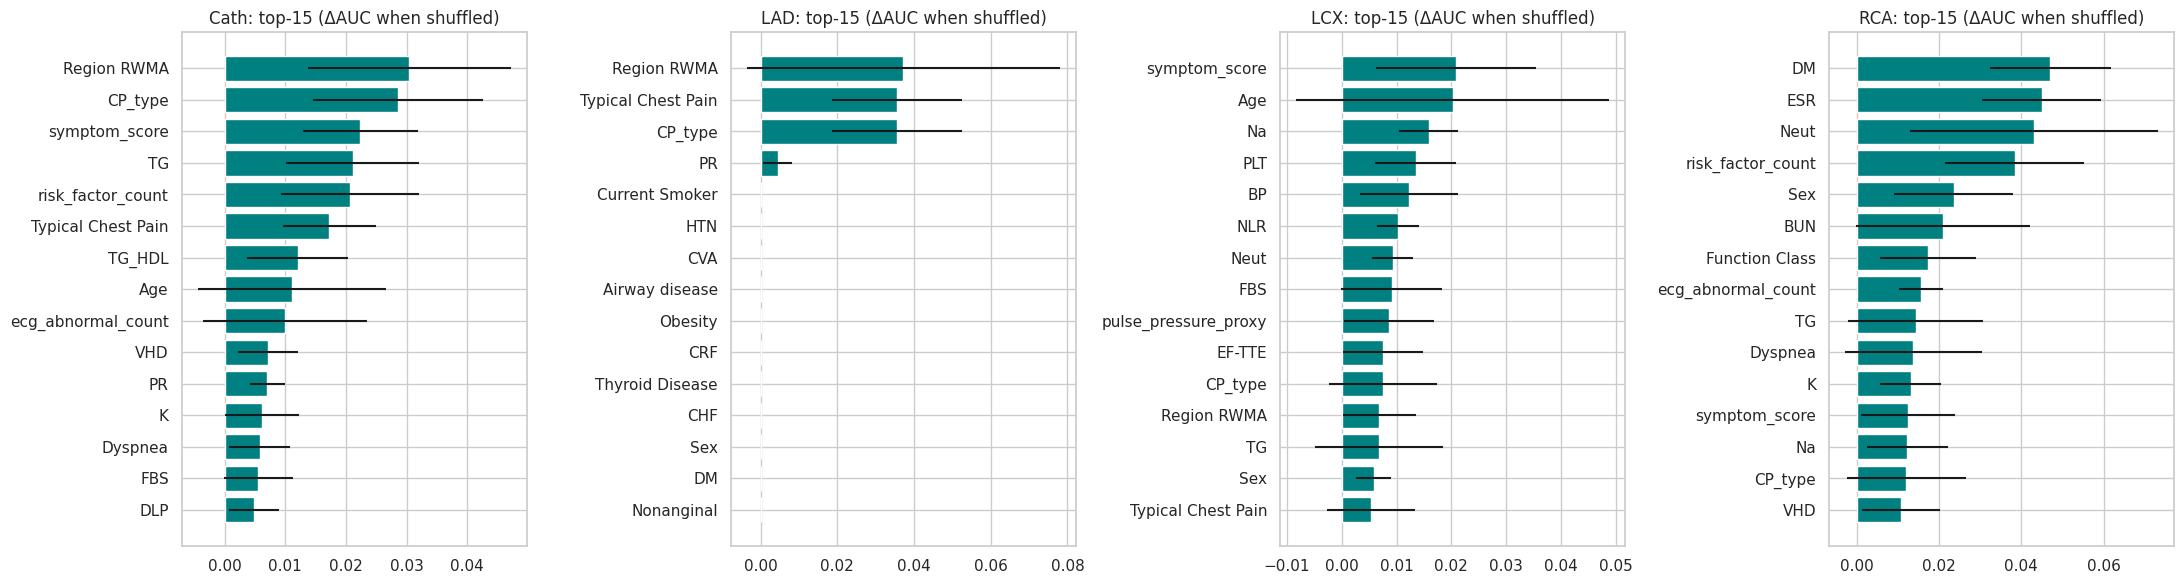

In [30]:
imp={}
for t in TARGETS:
    r=permutation_importance(best_est[t],X_te,Y_te[t],scoring='roc_auc',n_repeats=30,random_state=SEED,n_jobs=-1)
    imp[t]=pd.DataFrame({'importance':r.importances_mean,'std':r.importances_std},index=FEATURES).sort_values('importance',ascending=False)
    imp[t].to_csv(RES/f'{M}_perm_importance_{t}.csv')
fig,axes=plt.subplots(1,4,figsize=(22,6))
for ax,t in zip(axes,TARGETS):
    d=imp[t].head(15)[::-1]; ax.barh(d.index,d.importance,xerr=d['std'],color='teal'); ax.set_title(f'{t}: top-15 (ΔAUC when shuffled)')
plt.tight_layout(); plt.savefig(FIG/f'{M}_perm_importance.png',dpi=110); plt.show()

In [31]:
pd.concat({t:imp[t].head(10).importance.round(4).reset_index().rename(columns={'index':'feature'}) for t in TARGETS},axis=1)

Cath                            LAD                              LCX                            RCA           
              feature importance             feature importance               feature importance             feature importance
0         Region RWMA     0.0304         Region RWMA     0.0373         symptom_score     0.0208                  DM     0.0471
1             CP_type     0.0286  Typical Chest Pain     0.0355                   Age     0.0202                 ESR     0.0449
2       symptom_score     0.0224             CP_type     0.0355                    Na     0.0159                Neut     0.0431
3                  TG     0.0211                  PR     0.0045                   PLT     0.0135   risk_factor_count     0.0384
4   risk_factor_count     0.0207      Current Smoker     0.0000                    BP     0.0123                 Sex     0.0236
5  Typical Chest Pain     0.0172                 HTN     0.0000                   NLR     0.0102                 BUN     0.0210
6              TG_HDL     0.0120                 CVA     0.0000                  Neut     0.0093      Function Class     0.0174
7                 Age     0.0111      Airway disease     0.0000                   FBS     0.0091  ecg_abnormal_count     0.0156
8  ecg_abnormal_count     0.0099             Obesity     0.0000  pulse_pressure_proxy     0.0086                  TG     0.0144
9                 VHD     0.0071                 CRF     0.0000                EF-TTE     0.0076             Dyspnea     0.0138

## 16. Save fitted pipelines and probabilities

In [32]:
for t in TARGETS: joblib.dump(best_est[t],MOD/f'{M}_{t}.joblib')
joblib.dump(meta,MOD/f'{M}_stacked_Cath.joblib')
pd.DataFrame({t:test_proba[t] for t in TARGETS}|{'stacked_Cath':p_meta,'patient_idx':te.patient_idx.values}).to_csv(RES/f'{M}_test_proba.csv',index=False)
pd.DataFrame({t:oof[t] for t in TARGETS}|{'patient_idx':tr.patient_idx.values}).to_csv(RES/f'{M}_oof_train_proba.csv',index=False)
best_tbl.to_csv(RES/f'{M}_best_cv_summary.csv'); best_params.to_csv(RES/f'{M}_best_params.csv'); baseline.to_csv(RES/f'{M}_baseline.csv')
print('saved:',sorted(p.name for p in RES.glob(f'{M}_*'))[:30])

saved: ['lr_baseline.csv', 'lr_best_cv_summary.csv', 'lr_best_params.csv', 'lr_cv_fold_study.csv', 'lr_cv_grid_Cath.csv', 'lr_cv_grid_LAD.csv', 'lr_cv_grid_LCX.csv', 'lr_cv_grid_RCA.csv', 'lr_cv_random_Cath.csv', 'lr_cv_random_LAD.csv', 'lr_cv_random_LCX.csv', 'lr_cv_random_RCA.csv', 'lr_nested_cv.csv', 'lr_oof_train_proba.csv', 'lr_perm_importance_Cath.csv', 'lr_perm_importance_LAD.csv', 'lr_perm_importance_LCX.csv', 'lr_perm_importance_RCA.csv', 'lr_test_metrics.csv', 'lr_test_metrics_direct.csv', 'lr_test_proba.csv']


## 17. Summary

In [33]:
summary=test_tbl[test_tbl.threshold_rule=='youden'].set_index('target')[['accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc']].round(3)
summary.loc['Cath (stacked)']=st[st.threshold_rule=='youden'][['accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc']].iloc[0].round(3)
summary

,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc
target,,,,,,,,
Cath,0.836,0.814,0.864,0.765,0.905,0.884,0.928,0.973
LAD,0.656,0.647,0.694,0.600,0.714,0.704,0.762,0.832
LCX,0.639,0.652,0.720,0.583,0.545,0.621,0.754,0.704
RCA,0.557,0.593,0.739,0.447,0.447,0.557,0.665,0.586
Cath (stacked),0.852,0.844,0.864,0.824,0.927,0.894,0.928,0.973
